In [47]:
import argparse
import subprocess
from os import listdir
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import os.path
import glob
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 10]
%matplotlib inline

In [48]:
def get_uniques(sqanti, ref, acc, tool, version, name):
    # df reduction
    sqanti_genes = sqanti[['isoform', 'associated_transcript', 'structural_category']]
    sqanti_old = sqanti_genes.loc[sqanti_genes['associated_transcript'] != 'novel']
    sqanti_ref_full = sqanti_old.loc[sqanti_old['associated_transcript'].isin(ref['genes'])]
    # sqanti_ref_full = sqanti_ref.loc[sqanti_ref['structural_category'] == 'full-splice_match']
    merged = sqanti_ref_full['isoform'].str.split('.').str[0] + '_' + sqanti_ref_full['associated_transcript'] + '.' + acc + '.' + tool + '.' + version
    merged = sqanti_ref_full['isoform'].str.split('.').str[0] + '_' + sqanti_ref_full[
        'associated_transcript']

    merged_values = merged.value_counts().to_frame()
    merged_values.columns = ['values']
    merged_values['accession'] = acc
    merged_values['tool'] = tool
    merged_values['version'] = version
    merged_values['reference'] = name
    return merged_values

In [49]:
files = [
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at6923_liftoff_sqanti/at6923-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at6929_liftoff_sqanti/at6929-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at7143_liftoff_sqanti/at7143-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at8285_liftoff_sqanti/at8285-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9104_liftoff_sqanti/at9104-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9336_liftoff_sqanti/at9336-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9503_liftoff_sqanti/at9503-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9578_liftoff_sqanti/at9578-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9744_liftoff_sqanti/at9744-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9762_liftoff_sqanti/at9762-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9806_liftoff_sqanti/at9806-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9830_liftoff_sqanti/at9830-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9847_liftoff_sqanti/at9847-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9852_liftoff_sqanti/at9852-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9879_liftoff_sqanti/at9879-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9883_liftoff_sqanti/at9883-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/at9900_liftoff_sqanti/at9900-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_pb/col0_liftoff_sqanti/col0-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at6923_liftoff_sqanti/at6923-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at6929_liftoff_sqanti/at6929-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at7143_liftoff_sqanti/at7143-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at8285_liftoff_sqanti/at8285-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9104_liftoff_sqanti/at9104-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9336_liftoff_sqanti/at9336-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9503_liftoff_sqanti/at9503-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9578_liftoff_sqanti/at9578-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9744_liftoff_sqanti/at9744-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9762_liftoff_sqanti/at9762-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9806_liftoff_sqanti/at9806-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9830_liftoff_sqanti/at9830-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9847_liftoff_sqanti/at9847-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9852_liftoff_sqanti/at9852-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9879_liftoff_sqanti/at9879-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9883_liftoff_sqanti/at9883-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/at9900_liftoff_sqanti/at9900-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v2/collapse_tama/col0_liftoff_sqanti/col0-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at6923_liftoff_sqanti/at6923-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at6929_liftoff_sqanti/at6929-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at7143_liftoff_sqanti/at7143-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at8285_liftoff_sqanti/at8285-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9104_liftoff_sqanti/at9104-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9336_liftoff_sqanti/at9336-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9503_liftoff_sqanti/at9503-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9578_liftoff_sqanti/at9578-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9744_liftoff_sqanti/at9744-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9762_liftoff_sqanti/at9762-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9806_liftoff_sqanti/at9806-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9830_liftoff_sqanti/at9830-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9847_liftoff_sqanti/at9847-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9852_liftoff_sqanti/at9852-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9879_liftoff_sqanti/at9879-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9883_liftoff_sqanti/at9883-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/at9900_liftoff_sqanti/at9900-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_pb/col0_liftoff_sqanti/col0-pb-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at6923_liftoff_sqanti/at6923-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at6929_liftoff_sqanti/at6929-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at7143_liftoff_sqanti/at7143-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at8285_liftoff_sqanti/at8285-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9104_liftoff_sqanti/at9104-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9336_liftoff_sqanti/at9336-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9503_liftoff_sqanti/at9503-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9578_liftoff_sqanti/at9578-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9744_liftoff_sqanti/at9744-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9762_liftoff_sqanti/at9762-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9806_liftoff_sqanti/at9806-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9830_liftoff_sqanti/at9830-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9847_liftoff_sqanti/at9847-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9852_liftoff_sqanti/at9852-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9879_liftoff_sqanti/at9879-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9883_liftoff_sqanti/at9883-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/at9900_liftoff_sqanti/at9900-tama-vs-liftoff_classification.txt',
        '/ebio/abt6_projects7/dliso/dlis/leon_pipeline/output/v3/collapse_tama/col0_liftoff_sqanti/col0-tama-vs-liftoff_classification.txt']

In [50]:
ref_names = ['Busco', 'NLR', 'Housekeeping']
references = ['input/sqanti/busco_Araport11_20221221.txt',
      'input/sqanti/nlrs_in_orthogroups_20221221.txt',
      'input/sqanti/arat_housekeeping.txt']

# files = ["/home/leon/Documents/master_thesis/Analysis/sqanti/at9852-tama-vs-liftoff_v2_classification.txt", "/home/leon/Documents/master_thesis/Analysis/sqanti/at9852-tama-vs-liftoff_v3_classification.txt"]
# files = glob.glob("/home/leon/Documents/master_thesis/Analysis/sqanti/v*/*")

In [51]:
df_all = pd.DataFrame()
l = 0
# for everey reference, do all counting and append to df
for r_path, r_name in zip(references, ref_names):
    ref = pd.read_csv(r_path, header=None, names=['genes'])
    for path in tqdm(files, desc='files'):
        #df = pd.read_csv(path, sep="\t")
        basename = os.path.basename(path)
        # v = basename.split('_')[1]
        v = path.split('/')[7]
        #if v != 'v2':
        #    continue
        acc = basename.split('-')[0]
        tool = basename.split('-')[1]
        df = pd.read_csv(path, sep="\t")
        values = get_uniques(df, ref, acc, tool, v, r_name)
        l += len(values) #check if concat worked as inteded
        df_all = pd.concat([df_all, values])
df_all.to_csv('input/sqanti/all_raw_incl_partially_splices.tsv', sep='\t', header=True)

files:   0%|          | 0/72 [00:00<?, ?it/s]

files:   0%|          | 0/72 [00:00<?, ?it/s]

files:   0%|          | 0/72 [00:00<?, ?it/s]

In [52]:
df_all['log_val'] = np.log(df_all['values'])
df_all['bin'] = df_all['values']
df_all['bin'][df_all['bin'] >= 50] = 50
print(df_all)
print(l)
df_all.to_csv('all_incl_partially_splices.tsv', sep='\t', header=True)

/tmp/ipykernel_46646/1301026572.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_all['bin'][df_all['bin'] >= 50] = 50


                    values accession  tool version     reference   log_val  \
PB_AT5G13630.1         403    at6923    pb      v2         Busco  5.998937   
PB_AT1G62750.1         193    at6923    pb      v2         Busco  5.262690   
PB_AT5G53460.1         151    at6923    pb      v2         Busco  5.017280   
PB_AT3G46970.1         141    at6923    pb      v2         Busco  4.948760   
PB_AT1G42970.1         121    at6923    pb      v2         Busco  4.795791   
...                    ...       ...   ...     ...           ...       ...   
G11801_AT4G31930.1       1      col0  tama      v3  Housekeeping  0.000000   
G5791_AT2G35360.1        1      col0  tama      v3  Housekeeping  0.000000   
G11491_AT4G27540.1       1      col0  tama      v3  Housekeeping  0.000000   
G6451_AT2G44525.1        1      col0  tama      v3  Housekeeping  0.000000   
G8080_AT3G20010.1        1      col0  tama      v3  Housekeeping  0.000000   

                    bin  
PB_AT5G13630.1       50  
PB_AT1G6275

In [53]:
# ref_specific dfs
busco = df_all[df_all['reference'] == 'Busco']
nlr = df_all[df_all['reference'] == 'NLR']
house = df_all[df_all['reference'] == 'Housekeeping']

In [54]:
busco_test = busco.reset_index()
busco_test.columns

Index(['index', 'values', 'accession', 'tool', 'version', 'reference',
       'log_val', 'bin'],
      dtype='object')

In [55]:
busco_test['geneid'] = busco_test['index'].str.split('_').str[1]

In [56]:
busco_test[busco_test['geneid'] == 'AT3G07040.1']

,index,values,accession,tool,version,reference,log_val,bin,geneid
895,PB_AT3G07040.1,13,at6923,pb,v2,Busco,2.564949,13,AT3G07040.1
6555,PB_AT3G07040.1,1,at6929,pb,v2,Busco,0.000000,1,AT3G07040.1
10835,PB_AT3G07040.1,10,at8285,pb,v2,Busco,2.302585,10,AT3G07040.1
14415,PB_AT3G07040.1,8,at9104,pb,v2,Busco,2.079442,8,AT3G07040.1
21459,PB_AT3G07040.1,7,at9503,pb,v2,Busco,1.945910,7,AT3G07040.1
24720,PB_AT3G07040.1,9,at9578,pb,v2,Busco,2.197225,9,AT3G07040.1
27176,PB_AT3G07040.1,21,at9744,pb,v2,Busco,3.044522,21,AT3G07040.1
34613,PB_AT3G07040.1,7,at9806,pb,v2,Busco,1.945910,7,AT3G07040.1
40675,PB_AT3G07040.1,16,at9847,pb,v2,Busco,2.772589,16,AT3G07040.1
44427,PB_AT3G07040.1,8,at9852,pb,v2,Busco,2.079442,8,AT3G07040.1


In [57]:
print(busco[(busco['version'] == 'v3') & (busco['tool'] == 'tama') & (busco['accession'] == 'col0')]) # compare v2 vs v3, e.g. G13748_AT5G13630.1. and look at the expected isoforms (arabidopsis.org)

                    values accession  tool version reference   log_val  bin
G13237_AT5G13630.1     403      col0  tama      v3     Busco  5.998937   50
G2195_AT1G42970.1      239      col0  tama      v3     Busco  5.476464   50
G3043_AT1G62750.1      212      col0  tama      v3     Busco  5.356586   50
G13174_AT5G12860.1     184      col0  tama      v3     Busco  5.214936   50
G10224_AT4G04640.1     184      col0  tama      v3     Busco  5.214936   50
...                    ...       ...   ...     ...       ...       ...  ...
G11900_AT4G33170.1       1      col0  tama      v3     Busco  0.000000    1
G3656_AT1G72640.1        1      col0  tama      v3     Busco  0.000000    1
G3631_AT1G72190.1        1      col0  tama      v3     Busco  0.000000    1
G11948_AT4G33910.1       1      col0  tama      v3     Busco  0.000000    1
G8164_AT3G21290.1        1      col0  tama      v3     Busco  0.000000    1

[3372 rows x 7 columns]


In [58]:
# ref_comparisons
busco_nlr = df_all[(df_all['reference'] == 'Busco') | (df_all['reference'] == 'NLR')]
print(busco_nlr)
busco_nlr_v2 = busco_nlr[busco_nlr['version'] == 'v2']
busco_nlr_v2_pb = busco_nlr[busco_nlr['tool'] == 'pb']
busco_nlr_v2_tama = busco_nlr[busco_nlr['tool'] == 'tama']
busco_nlr_v3 = busco_nlr[busco_nlr['version'] == 'v3']
print(busco_nlr_v2)
busco_house = df_all[(df_all['reference'] == 'Busco') | (df_all['reference'] == 'Housekeeping')]
nlr_house = df_all[(df_all['reference'] == 'NLR') | (df_all['reference'] == 'Housekeeping')]

                     values accession  tool version reference   log_val  bin
PB_AT5G13630.1          403    at6923    pb      v2     Busco  5.998937   50
PB_AT1G62750.1          193    at6923    pb      v2     Busco  5.262690   50
PB_AT5G53460.1          151    at6923    pb      v2     Busco  5.017280   50
PB_AT3G46970.1          141    at6923    pb      v2     Busco  4.948760   50
PB_AT1G42970.1          121    at6923    pb      v2     Busco  4.795791   50
...                     ...       ...   ...     ...       ...       ...  ...
G799_AT1G12210.1          1      col0  tama      v3       NLR  0.000000    1
G13550_AT5G18370.1        1      col0  tama      v3       NLR  0.000000    1
G10814_AT4G16990.1        1      col0  tama      v3       NLR  0.000000    1
G14307_AT5G38340.1        1      col0  tama      v3       NLR  0.000000    1
G10477_AT4G12020.11       1      col0  tama      v3       NLR  0.000000    1

[249033 rows x 7 columns]
                     values accession  tool versi

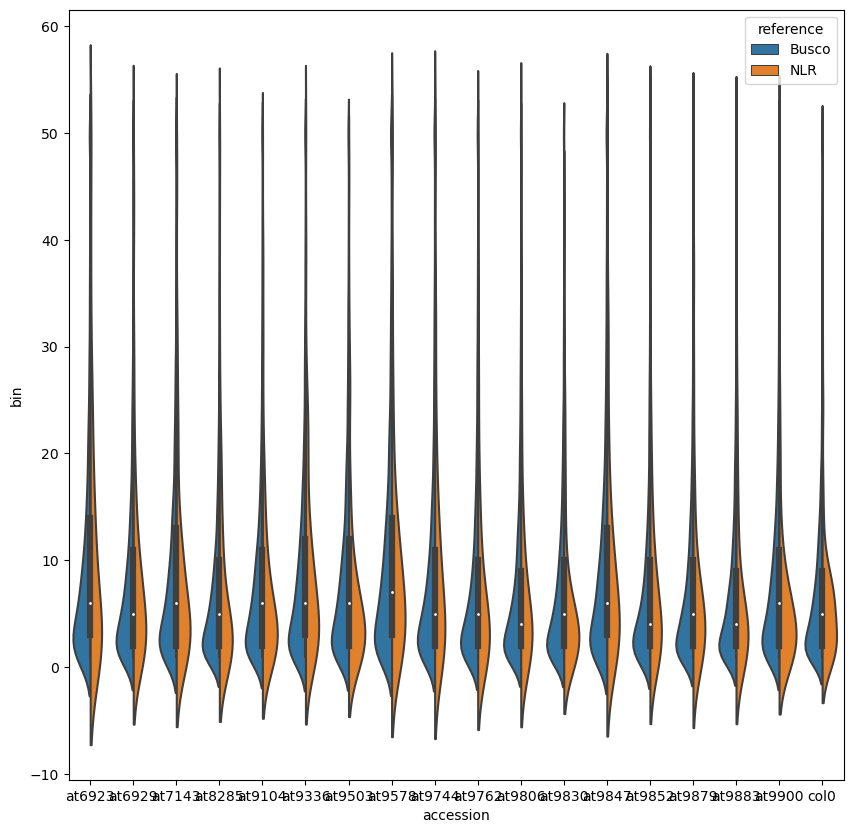

In [59]:
fig = plt.figure()
sns.violinplot(data=busco_nlr_v2, y='bin', x='accession', hue='reference', split=True)
plt.show()
# fig.savefig('/home/leon/Documents/master_thesis/Analysis/sqanti/normal.png', dpi=fig.dpi)

<Figure size 1000x1000 with 0 Axes>

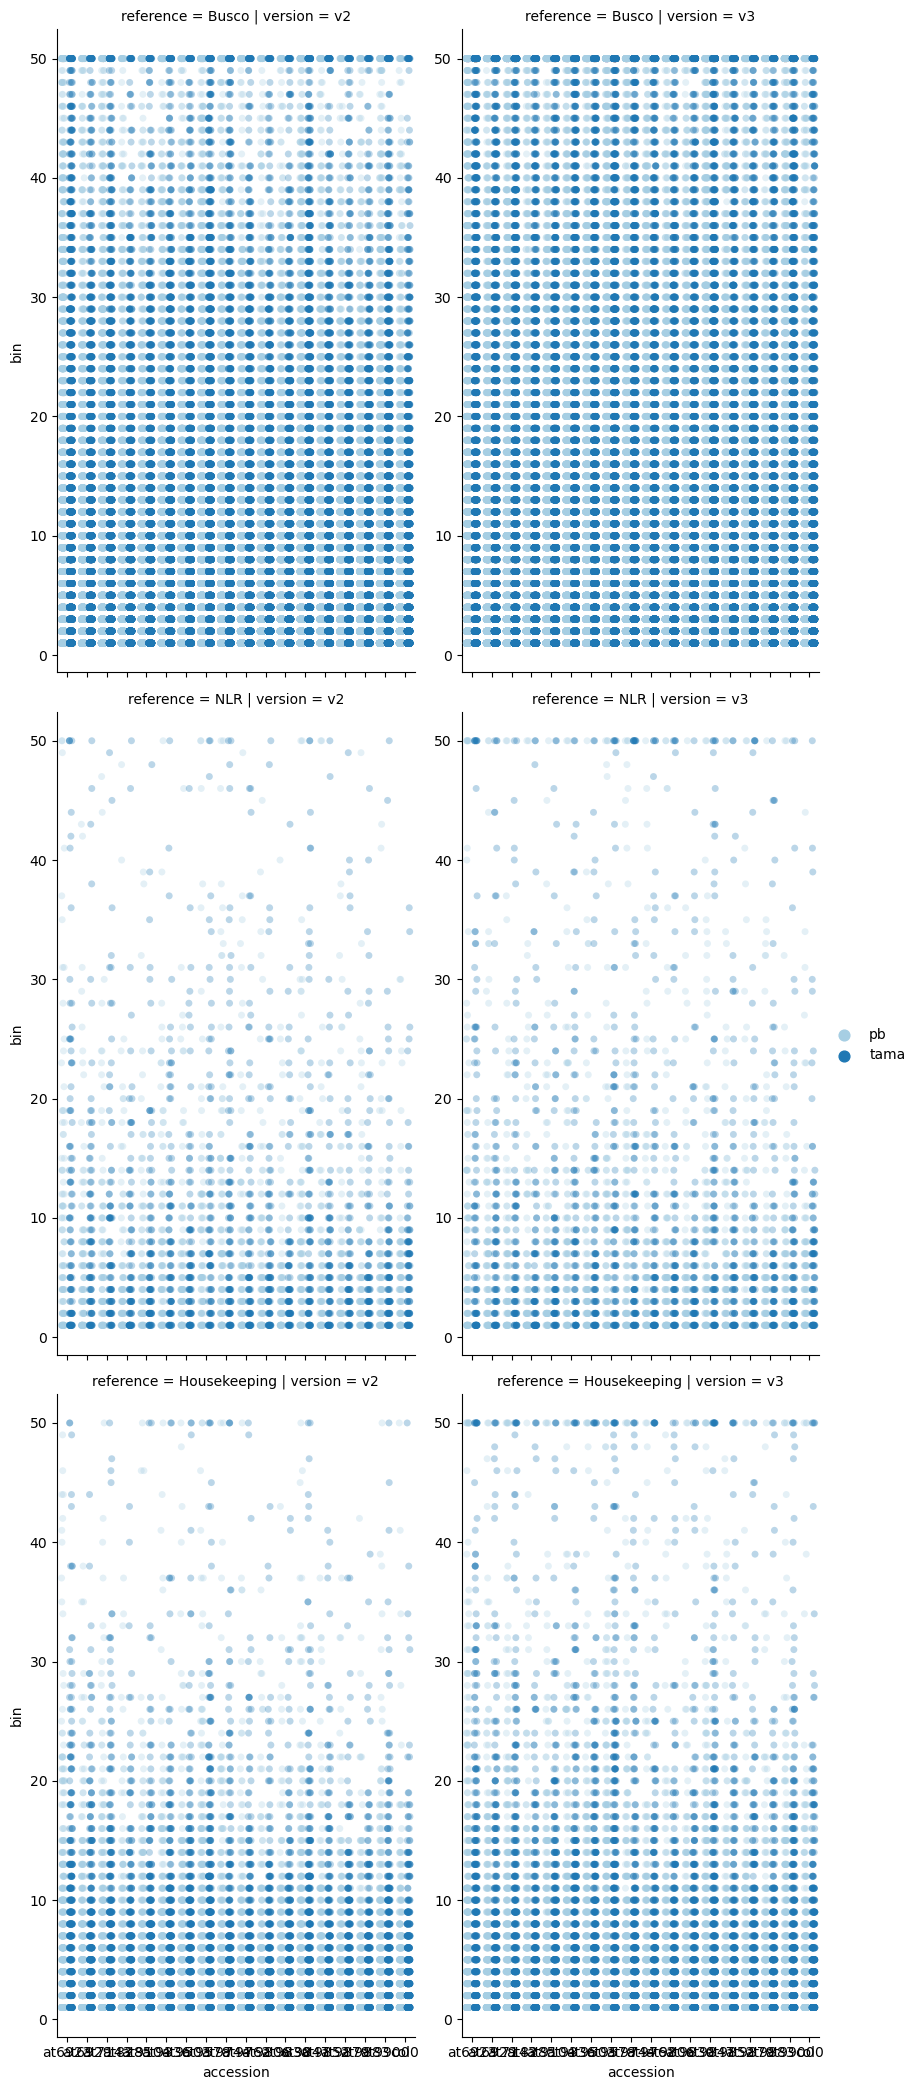

In [60]:
fig = plt.figure()
# grid = sns.FacetGrid(df_all, row='version', col='tool', height=7)
# grid.map_dataframe(sns.stripplot, y='bin', x='accession', hue='reference', palette='Paired', dodge=True, alpha=0.1, jitter=0.15)
grid = sns.FacetGrid(df_all, row='reference', col='version', height=7, aspect=0.6, sharey=False)
grid.map_dataframe(sns.stripplot, y='bin', x='accession', hue='tool', palette='Paired', dodge=True, alpha=0.3, jitter=0.15)

# grid = sns.FacetGrid(df_all[df_all['accession'] == 'at9852'], row='reference', col='tool', height=3, aspect=2, sharey=False)
# grid.map_dataframe(sns.histplot, x='values', hue='version', palette='Paired', multiple='dodge', bins=25, shrink=0.8, kde=True)
# grid.map_dataframe(sns.ecdfplot, x='values', hue='version', palette='Paired')

grid.add_legend()
plt.show()

<AxesSubplot:xlabel='bin', ylabel='accession'>

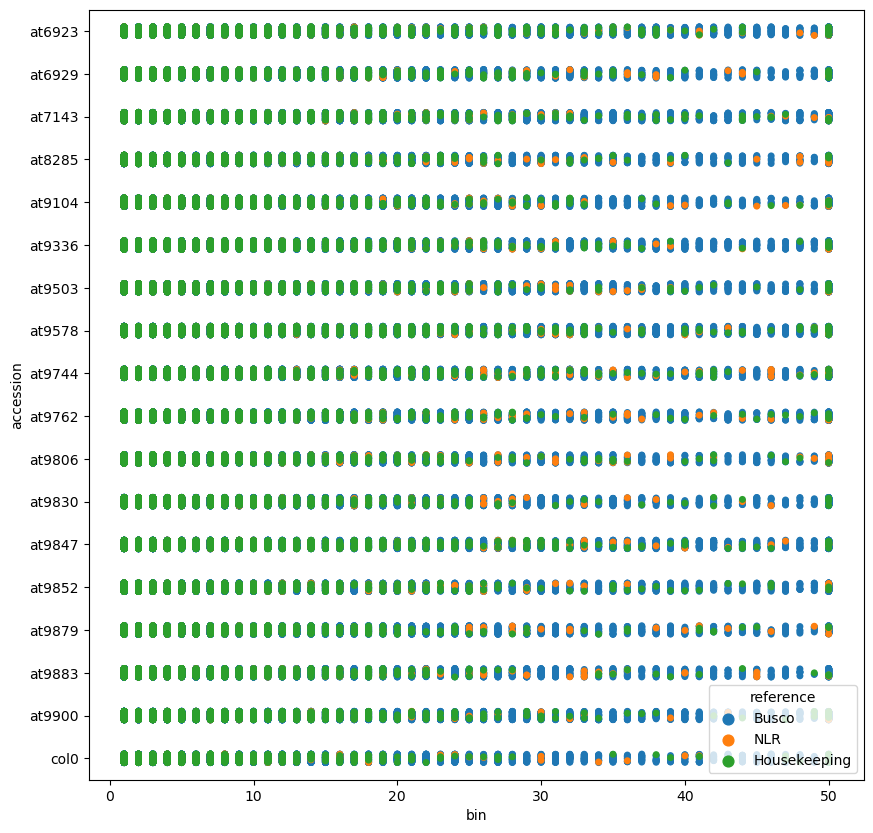

In [42]:
sns.stripplot(x='bin', y='accession', hue='reference', data=df_all)

In [ ]:
fig.show()